In [1]:
#THIS NOTEBOOK COMPARES STRAIGHT JOBACK, THE BASELINE (RANDOM INITIALISATION) AND THE HYBRID (JOBACK-PRETRAINED, THEN FINE-TUNED) FOR dHfus
#THE MODELS WERE TRAINED BY run_baseline.py AND run_hybrid.py, THIS NOTEBOOK ONLY READS THE RESULTS. EACH HYBRID SEED USES THE SAME SPLIT AS THE BASELINE OF THAT SEED (PAIRED)
import pandas as pd                          #IMPORTS THE DATA FRAME HANDLING LIBRARY
import numpy as np                           #IMPORTS THE NUMERICAL LIBRARY
import matplotlib.pyplot as plt              #IMPORTS THE PLOTTING LIBRARY
from scipy import stats                      #IMPORTS THE STATISTICS LIBRARY

hyb = pd.read_csv("hybrid_seeds_dHfus.csv")
print("Rows:", len(hyb), "| seeds:", [int(s) for s in sorted(hyb["seed"].unique())])            #SHOULD BE 10 ROWS, SEEDS 0-9
print(pd.read_csv("hybrid_pretrain_metrics.csv").round(3).to_string(index=False))               #HOW WELL THE PRETRAINED MODEL REPRODUCES JOBACK'S OWN PREDICTIONS
print("Epochs trained per seed:", hyb["epochs"].tolist())

Rows: 10 | seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
 n_pseudo_labels  test_mae  test_rmse  epochs
            9449     0.939      2.392      50
Epochs trained per seed: [27, 47, 13, 16, 24, 34, 30, 30, 24, 11]


In [2]:
#PAIRED COMPARISON: HYBRID VS. BASELINE ACROSS SEEDS (SAME SPLIT AND SAME TEST MOLECULES PER SEED)
rows = []
for metric in ["mae", "rmse"]:
    h, b = hyb[f"hybrid_{metric}"].values, hyb[f"baseline_{metric}"].values
    t_stat, p_val = stats.ttest_rel(h, b)
    rows.append(dict(Metric=metric.upper(),
                     Baseline=f"{b.mean():.3f} ± {b.std(ddof=1):.3f}",
                     Hybrid=f"{h.mean():.3f} ± {h.std(ddof=1):.3f}",
                     Straight_Joback=f"{hyb[f'joback_{metric}'].mean():.3f} ± {hyb[f'joback_{metric}'].std(ddof=1):.3f}",
                     Hybrid_minus_baseline=h.mean() - b.mean(), Paired_p=p_val,
                     Seeds_hybrid_better=int((h < b).sum())))
hybrid_summary = pd.DataFrame(rows)
print(hybrid_summary.round(3).to_string(index=False))
hybrid_summary.to_csv("dHfus_hybridization_comparison.csv", index=False)
print(f"Joback valid on {hyb['n_joback_valid'].mean():.0f} of {hyb['n_test'].mean():.0f} test molecules on average (the rest have unassignable groups)")

Metric      Baseline        Hybrid Straight_Joback  Hybrid_minus_baseline  Paired_p  Seeds_hybrid_better
   MAE 1.816 ± 0.139 1.796 ± 0.194   2.866 ± 0.246                 -0.020     0.388                    6
  RMSE 3.359 ± 1.037 3.348 ± 1.083   4.608 ± 0.627                 -0.011     0.693                    5
Joback valid on 404 of 450 test molecules on average (the rest have unassignable groups)


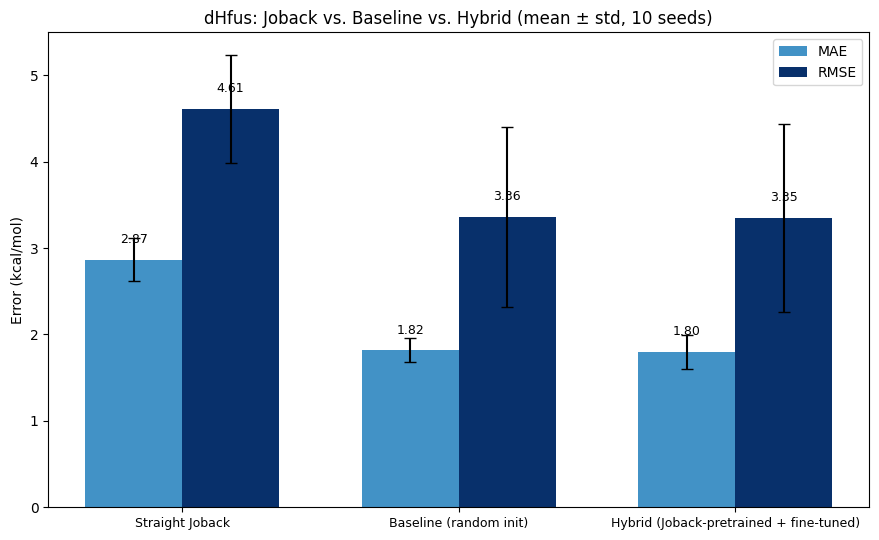

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.5))
models = [("Straight Joback", "joback"), ("Baseline (random init)", "baseline"), ("Hybrid (Joback-pretrained + fine-tuned)", "hybrid")]
x = np.arange(len(models))
width = 0.35
for i, (metric, color) in enumerate([("mae", "#4292c6"), ("rmse", "#08306b")]):
    means = [hyb[f"{key}_{metric}"].mean() for _, key in models]
    stds = [hyb[f"{key}_{metric}"].std() for _, key in models]
    bars = ax.bar(x + (i - 0.5) * width, means, width, yerr=stds, capsize=4, color=color, label=metric.upper())
    for bar, v in zip(bars, means):
        ax.annotate(f"{v:.2f}", xy=(bar.get_x() + bar.get_width() / 2, v), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([m for m, _ in models], fontsize=9)
ax.set_ylabel("Error (kcal/mol)")
ax.set_title("dHfus: Joback vs. Baseline vs. Hybrid (mean ± std, 10 seeds)")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_hybridization_comparison.png", dpi=150)
plt.show()

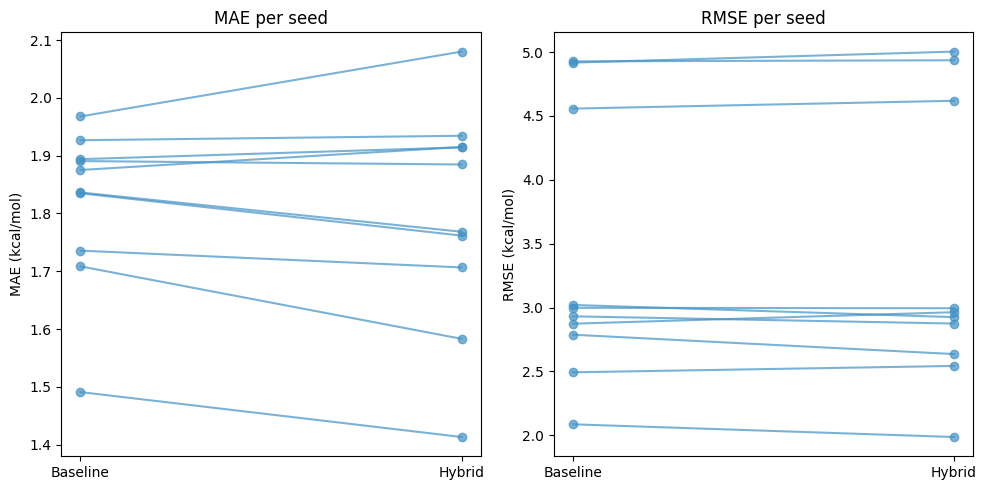

In [4]:
#PER-SEED PAIRED VIEW: EACH LINE JOINS THE BASELINE AND THE HYBRID FOR THE SAME SEED (SAME SPLIT)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, metric in zip(axes, ["mae", "rmse"]):
    for _, r in hyb.iterrows():
        ax.plot([0, 1], [r[f"baseline_{metric}"], r[f"hybrid_{metric}"]], marker="o", color="#4292c6", alpha=0.7)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Baseline", "Hybrid"])
    ax.set_ylabel(f"{metric.upper()} (kcal/mol)")
    ax.set_title(f"{metric.upper()} per seed")
plt.tight_layout()
plt.savefig("plots_dHfus_hybrid_paired_seeds.png", dpi=150)
plt.show()